# Weight-Shortcut Error Decomposition

This confirmatory experiment asks why a model follows the heavier side when exact torque predicts the opposite answer.

[实验设置与运行说明](../../../docs/experiment_notes/08_appendix_error_structure/872981c7498aa68c.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the weight-shortcut decomposition protocol
cell_stage('Freezing models, sites, geometry, interventions, and causal gates')
import hashlib
import json
from datetime import datetime, timezone

# Run qwen9b first, then qwen27b without changing any other setting.
# gemma12b is optional because its earlier manifest contained almost no
# initially correct weight-conflict cases.
MODEL_KEY = 'qwen9b'

MODEL_SPECS = {
    'qwen9b': {
        'model_id': 'Qwen/Qwen3.5-9B',
        'model_slug': 'Qwen__Qwen3.5-9B',
        'expected_layers': 32,
        'revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
        'sites': (
            (16, 'options_tokens', 'factor_composition'),
            (27, 'final_prompt_token', 'late_answer'),
        ),
        'confirmatory': True,
    },
    'qwen27b': {
        'model_id': 'Qwen/Qwen3.5-27B',
        'model_slug': 'Qwen__Qwen3.5-27B__373612cb',
        'expected_layers': 64,
        'revision': '373612cb4f9288fcf550b526d86d85febedd9801',
        'sites': (
            (48, 'options_tokens', 'factor_composition'),
            (63, 'final_prompt_token', 'late_answer'),
        ),
        'confirmatory': True,
    },
    'gemma12b': {
        'model_id': 'google/gemma-4-12B-it',
        'model_slug': 'google__gemma-4-12B-it',
        'expected_layers': 48,
        'revision': '707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7',
        'sites': (
            (25, 'options_tokens', 'factor_composition'),
            (41, 'final_prompt_token', 'late_answer'),
        ),
        'confirmatory': False,
    },
}
PRIMARY_MODEL_KEYS = ('qwen9b', 'qwen27b')
assert MODEL_KEY in MODEL_SPECS
SPEC = MODEL_SPECS[MODEL_KEY]
MODEL_ID = SPEC['model_id']
MODEL_SLUG = SPEC['model_slug']
MODEL_REVISION = SPEC['revision']
EXPECTED_LAYER_COUNT = SPEC['expected_layers']
FROZEN_SITES = SPEC['sites']
CAPTURE_LAYERS = tuple(sorted({layer for layer, _, _ in FROZEN_SITES}))
PRIMARY_SITE_LABEL = 'factor_composition'
SECONDARY_SITE_LABEL = 'late_answer'

MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
SEED = 20260827
MARGIN_BINS = ('hard', 'moderate')
OUTCOMES = ('left', 'right')
FAMILIES_PER_STRATUM = 12
EXPECTED_FAMILIES = len(MARGIN_BINS) * len(OUTCOMES) * FAMILIES_PER_STRATUM
SCENE_ROLES = (
    'base', 'weight_neutral_source', 'weight_aligned_source',
    'weight_amplified_source', 'distance_strengthened_source',
    'distance_weakened_source',
)
INTERVENTIONS = (
    'self_replay',
    'weight_neutral_norm', 'weight_align_norm',
    'distance_strengthen_norm', 'random_rescue_norm',
    'weight_amplify_norm', 'distance_weaken_norm',
    'random_induction_norm',
)
RESCUE_INTERVENTIONS = (
    'weight_neutral_norm', 'weight_align_norm',
    'distance_strengthen_norm',
)
INDUCTION_INTERVENTIONS = (
    'weight_amplify_norm', 'distance_weaken_norm',
)
CAPTURE_BATCH_SIZE = 1 if MODEL_KEY == 'qwen27b' else 2
PATCH_CONDITION_BATCH_SIZE = 1 if MODEL_KEY == 'qwen27b' else 2
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
MIN_PRIMARY_COHORT = 8
CAUSAL_SESOI_LOGODDS = 0.20
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
# Deltas are stored in bfloat16 before capture. Requiring 1e-4 relative
# equality is below bfloat16's numerical resolution; 2% still detects any
# scientifically meaningful mismatch while allowing expected quantization.
NORM_RELATIVE_TOLERANCE = 0.02
IMAGE_TOKEN_ID_OVERRIDE = None
FIXED_PROMPT_STYLE = 'semantic'

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'weight_shortcut_error_decomposition_v1'
)
MANIFEST_PATH = SHARED_ROOT / 'decomposition_manifest.jsonl'
MANIFEST_LOCK_PATH = SHARED_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SCENE_DIR = SHARED_ROOT / 'rendered_scenes'
OUTPUT_ROOT = SHARED_ROOT / 'models' / MODEL_SLUG
SHARD_DIR = OUTPUT_ROOT / 'family_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
CROSS_MODEL_DIR = SHARED_ROOT / 'cross_model_analysis'
for path in (
    SHARED_ROOT, SCENE_DIR, OUTPUT_ROOT, SHARD_DIR,
    ANALYSIS_DIR, FIGURE_DIR, CROSS_MODEL_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'weight-shortcut-decomposition-protocol-1.0',
    'analysis_status': 'prospective_confirmatory',
    'primary_models': list(PRIMARY_MODEL_KEYS),
    'models': {
        key: {
            'model_id': value['model_id'],
            'revision': value['revision'],
            'sites': [list(site) for site in value['sites']],
            'confirmatory': bool(value['confirmatory']),
        }
        for key, value in MODEL_SPECS.items()
    },
    'physical_design': {
        'stacks_per_side': 2,
        'units': [1, 5],
        'distance': [1, 6],
        'distinct_positions_within_side': True,
        'all_sources_preserve_exact_net_torque': True,
        'weight_sources_hold_distances_fixed': True,
        'distance_sources_hold_units_fixed': True,
    },
    'families_per_stratum': FAMILIES_PER_STRATUM,
    'strata': 'normalized torque margin by exact outcome',
    'base_condition': (
        'weight-only cue opposes exact torque and distance-only cue agrees'
    ),
    'rescue_cohort': 'base prediction equals the weight-only shortcut',
    'induction_cohort': 'base prediction equals exact torque',
    'primary_site': PRIMARY_SITE_LABEL,
    'secondary_site': SECONDARY_SITE_LABEL,
    'interventions': list(INTERVENTIONS),
    'norm_matching': (
        'all rescue directions share the minimum rescue-delta norm within '
        'family and site; all induction directions share the analogous norm'
    ),
    'primary_routes': {
        'overweighting': ['weight_neutral_norm', 'weight_amplify_norm'],
        'distance_underuse': [
            'distance_strengthen_norm', 'distance_weaken_norm'
        ],
    },
    'supportive_intervention': 'weight_align_norm',
    'direction_gate': (
        'cohort n >= 8; main lower 95% CI > 0.20 log odds; '
        'random-subtracted lower CI > 0; both directional BH q < 0.05'
    ),
    'route_gate': 'both rescue and induction direction gates pass',
    'bootstrap_unit': 'independent six-scene family',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'selection_uses_model_outputs': False,
    'seed': SEED,
    'interpretation_limit': (
        'The experiment separates two causal explanations of one specified '
        'error class at frozen sites; it does not identify a unique circuit.'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_KEY, MODEL_ID, '@', MODEL_REVISION)
print('Confirmatory model:', bool(SPEC['confirmatory']))
print('Frozen primary/secondary sites:', FROZEN_SITES)
print('Independent in-range families:', EXPECTED_FAMILIES)
print('Shared output:', SHARED_ROOT)


Lock the weight-shortcut decomposition protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: qwen9b Qwen/Qwen3.5-9B @ c202236235762e1c871ad0ccb60c8ee5ba337b9a
Confirmatory model: True
Frozen primary/secondary sites: ((16, 'options_tokens', 'factor_composition'), (27, 'final_prompt_token', 'late_answer'))
Independent in-range families: 48
Shared output: /content/drive/MyDrive/VisualTorque/results/weight_shortcut_error_decomposition_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Independent in-range, four-stack, equal-net manifest


In [7]:
%%cell_progress 6/17 Build the independent in-range equal-net manifest
cell_stage('Enumerating four-stack weight conflicts and exact-net factor edits')
from collections import Counter, defaultdict
from itertools import combinations, product
import shutil

from visual_torque_toolkit.render import render_scene
from visual_torque_toolkit.world import Scene, Side, Stack

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

def sign(value):
    return int(value > 0) - int(value < 0)

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def stacks_from_shape(shape):
    lu1, ld1, lu2, ld2, ru1, rd1, ru2, rd2 = (
        int(value) for value in shape
    )
    return [
        {'side': 'left', 'distance': ld1, 'units': lu1},
        {'side': 'left', 'distance': ld2, 'units': lu2},
        {'side': 'right', 'distance': rd1, 'units': ru1},
        {'side': 'right', 'distance': rd2, 'units': ru2},
    ]

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

def shape_signature(shape):
    return canonical_signature(stacks_from_shape(shape))

def scene_features(shape):
    lu1, ld1, lu2, ld2, ru1, rd1, ru2, rd2 = (
        int(value) for value in shape
    )
    left_units = lu1 + lu2
    right_units = ru1 + ru2
    left_distance = ld1 + ld2
    right_distance = rd1 + rd2
    left_torque = lu1 * ld1 + lu2 * ld2
    right_torque = ru1 * rd1 + ru2 * rd2
    net_torque = left_torque - right_torque
    weight_score = left_units - right_units
    distance_score = left_distance - right_distance
    return {
        'left_units': int(left_units),
        'right_units': int(right_units),
        'left_distance_sum': int(left_distance),
        'right_distance_sum': int(right_distance),
        'left_torque': int(left_torque),
        'right_torque': int(right_torque),
        'net_torque': int(net_torque),
        'total_torque': int(left_torque + right_torque),
        'normalized_margin': float(
            abs(net_torque) / max(1, left_torque + right_torque)
        ),
        'weight_score': int(weight_score),
        'distance_score': int(distance_score),
        'strategy_predictions': {
            'exact_torque': outcome(net_torque),
            'weight_only': outcome(weight_score),
            'distance_only': outcome(distance_score),
        },
        'outcome': outcome(net_torque),
    }

def margin_bin(features):
    value = float(features['normalized_margin'])
    if 0.08 <= value < 0.22:
        return 'hard'
    if 0.22 <= value < 0.45:
        return 'moderate'
    return None

def is_base(features):
    predictions = features['strategy_predictions']
    exact = predictions['exact_torque']
    return bool(
        exact != 'balanced'
        and predictions['weight_only'] not in ('balanced', exact)
        and predictions['distance_only'] == exact
        and abs(int(features['distance_score'])) >= 2
        and margin_bin(features) is not None
    )

def signatures_in(value):
    found = set()
    if isinstance(value, dict):
        stacks = value.get('stacks')
        if isinstance(stacks, list) and stacks and all(
            isinstance(stack, dict)
            and {'side', 'distance', 'units'} <= set(stack)
            for stack in stacks
        ):
            try:
                found.add(canonical_signature(stacks))
            except (TypeError, ValueError):
                pass
        for child in value.values():
            found.update(signatures_in(child))
    elif isinstance(value, list):
        for child in value:
            found.update(signatures_in(child))
    return found

dataset_rows = read_jsonl(DATASET_DIR / 'scenes.jsonl')
dataset_signatures = {
    canonical_signature(row['stacks']) for row in dataset_rows
}
prior_signatures = set()
results_root = PROJECT_ROOT / 'results'
prior_manifest_paths = []
if results_root.is_dir():
    prior_manifest_paths = sorted(
        path for path in results_root.rglob('*manifest*.jsonl')
        if SHARED_ROOT not in path.parents
    )
for path in tqdm(prior_manifest_paths, desc='Auditing prior geometries', unit='file'):
    try:
        rows = read_jsonl(path)
    except Exception:
        continue
    for row in rows:
        prior_signatures.update(signatures_in(row))
excluded_signatures = dataset_signatures | prior_signatures
print('Dataset / prior excluded geometries:',
      len(dataset_signatures), len(prior_signatures))

cell_stage('Indexing in-range two-stack-per-side scenes')
side_shapes = []
for distances in combinations(range(1, 7), 2):
    for units in product(range(1, 6), repeat=2):
        side_shapes.append((
            int(units[0]), int(distances[0]),
            int(units[1]), int(distances[1]),
        ))

pool = []
by_distances = defaultdict(list)
by_units = defaultdict(list)
for left in tqdm(side_shapes, desc='Indexing scene pool', unit='left-shape'):
    for right in side_shapes:
        shape = tuple(left + right)
        record = {
            'shape': shape,
            'signature': shape_signature(shape),
            'features': scene_features(shape),
        }
        pool.append(record)
        by_distances[(
            shape[1], shape[3], shape[5], shape[7]
        )].append(record)
        by_units[(
            shape[0], shape[2], shape[4], shape[6]
        )].append(record)

def role_candidates(base, role, unavailable):
    shape = base['shape']
    features = base['features']
    exact_sign = sign(features['net_torque'])
    shortcut_sign = sign(features['weight_score'])
    distance_key = (shape[1], shape[3], shape[5], shape[7])
    unit_key = (shape[0], shape[2], shape[4], shape[6])
    candidates = (
        by_distances[distance_key]
        if role.startswith('weight_') else by_units[unit_key]
    )
    valid = []
    for record in candidates:
        current = record['features']
        if record['signature'] in unavailable:
            continue
        if int(current['net_torque']) != int(features['net_torque']):
            continue
        if role == 'weight_neutral_source':
            keep = int(current['weight_score']) == 0
        elif role == 'weight_aligned_source':
            keep = sign(current['weight_score']) == exact_sign
        elif role == 'weight_amplified_source':
            keep = bool(
                sign(current['weight_score']) == shortcut_sign
                and abs(int(current['weight_score']))
                > abs(int(features['weight_score']))
            )
        elif role == 'distance_strengthened_source':
            keep = bool(
                sign(current['distance_score']) == exact_sign
                and abs(int(current['distance_score']))
                > abs(int(features['distance_score']))
            )
        elif role == 'distance_weakened_source':
            keep = bool(
                sign(current['distance_score']) == exact_sign
                and 0 < abs(int(current['distance_score']))
                < abs(int(features['distance_score']))
            )
        else:
            raise KeyError(role)
        if keep:
            valid.append(record)
    valid.sort(key=lambda row: (
        sum(abs(int(a) - int(b)) for a, b in zip(shape, row['shape'])),
        stable_key((role, shape, row['shape'])),
    ))
    return valid

base_by_stratum = defaultdict(list)
for record in pool:
    features = record['features']
    if not is_base(features):
        continue
    exact = features['outcome']
    base_by_stratum[(margin_bin(features), exact)].append(record)
for records in base_by_stratum.values():
    records.sort(key=lambda row: stable_key(('base', row['shape'])))

cell_stage('Selecting balanced, geometry-disjoint six-scene families')
selected = []
used_signatures = set(excluded_signatures)
source_roles = SCENE_ROLES[1:]
for current_margin in MARGIN_BINS:
    for exact_outcome in OUTCOMES:
        stratum = (current_margin, exact_outcome)
        chosen = 0
        for base in base_by_stratum[stratum]:
            if base['signature'] in used_signatures:
                continue
            provisional = set(used_signatures) | {base['signature']}
            records = {'base': base}
            complete = True
            for role in source_roles:
                candidates = role_candidates(base, role, provisional)
                if not candidates:
                    complete = False
                    break
                records[role] = candidates[0]
                provisional.add(candidates[0]['signature'])
            if not complete:
                continue
            family_id = 'decompose_' + stable_key((
                current_margin, exact_outcome,
                tuple(records[role]['shape'] for role in SCENE_ROLES),
            ))[:18]
            roles = {}
            for role, record in records.items():
                scene_id = family_id + '__' + role
                roles[role] = {
                    'scene_id': scene_id,
                    'image_filename': scene_id + '.png',
                    'stacks': stacks_from_shape(record['shape']),
                    'features': record['features'],
                }
            selected.append({
                'family_id': family_id,
                'split': 'confirmation',
                'diagnostic_cell': 'weight_conflict',
                'shortcut_type': 'weight',
                'margin_bin': current_margin,
                'base_outcome': exact_outcome,
                'roles': roles,
            })
            used_signatures.update(
                record['signature'] for record in records.values()
            )
            chosen += 1
            if chosen == FAMILIES_PER_STRATUM:
                break
        assert chosen == FAMILIES_PER_STRATUM, (
            stratum, chosen, len(base_by_stratum[stratum])
        )

selected.sort(key=lambda row: row['family_id'])
assert len(selected) == EXPECTED_FAMILIES
all_signatures = [
    canonical_signature(role['stacks'])
    for row in selected for role in row['roles'].values()
]
assert len(all_signatures) == len(set(all_signatures))
assert not (set(all_signatures) & excluded_signatures)

counts = Counter((
    row['margin_bin'], row['base_outcome']
) for row in selected)
assert set(counts.values()) == {FAMILIES_PER_STRATUM}
manifest_identity = {
    'schema_version': 'weight-shortcut-decomposition-manifest-1.0',
    'dataset_scenes_sha256': sha256_file(DATASET_DIR / 'scenes.jsonl'),
    'selection_uses_model_outputs': False,
    'all_scenes_disjoint_from_dataset_and_prior_manifests': True,
    'all_scenes_geometry_disjoint_within_manifest': True,
    'all_sources_preserve_base_net_torque': True,
    'all_units_in_range_1_to_5': True,
    'all_distances_in_range_1_to_6': True,
    'families': len(selected),
    'role_geometries': len(all_signatures),
    'stratum_counts': {
        '|'.join(key): int(value) for key, value in sorted(counts.items())
    },
    'selection_seed': SEED,
    'family_ids': [row['family_id'] for row in selected],
}
if MANIFEST_PATH.is_file() and MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == selected
else:
    write_jsonl_atomic(MANIFEST_PATH, selected)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

decomposition_manifest = read_jsonl(MANIFEST_PATH)
cell_stage('Rendering or verifying exact-net scene sextets')
for row in tqdm(
    decomposition_manifest, desc='Rendering decomposition families', unit='family'
):
    base_net = int(row['roles']['base']['features']['net_torque'])
    for role_name, role in row['roles'].items():
        assert int(role['features']['net_torque']) == base_net
        image_path = SCENE_DIR / role['image_filename']
        if image_path.is_file():
            continue
        stacks = tuple(
            Stack(
                stack_id=f'{role_name}_{index}',
                side=Side(str(stack['side'])),
                distance=int(stack['distance']),
                units=int(stack['units']),
            )
            for index, stack in enumerate(role['stacks'])
        )
        render_scene(Scene(role['scene_id'], stacks), image_path)

cell_stage('Caching rendered scenes on the Colab local SSD')
RUNTIME_SCENE_DIR = Path('/content/visualtorque_weight_decomposition_scenes_v1')
RUNTIME_SCENE_DIR.mkdir(parents=True, exist_ok=True)
scene_files = [
    role['image_filename']
    for row in decomposition_manifest for role in row['roles'].values()
]
for filename in tqdm(scene_files, desc='Caching rendered scenes', unit='image'):
    source = SCENE_DIR / filename
    destination = RUNTIME_SCENE_DIR / filename
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        shutil.copy2(source, destination)
assert all((RUNTIME_SCENE_DIR / name).is_file() for name in scene_files)

manifest_frame = pd.DataFrame([{
    'family_id': row['family_id'],
    'margin_bin': row['margin_bin'],
    'base_outcome': row['base_outcome'],
    'net_torque': row['roles']['base']['features']['net_torque'],
    'weight_score': row['roles']['base']['features']['weight_score'],
    'distance_score': row['roles']['base']['features']['distance_score'],
} for row in decomposition_manifest])
manifest_frame.to_csv(SHARED_ROOT / 'decomposition_manifest.csv', index=False)
display(manifest_frame.groupby([
    'margin_bin', 'base_outcome'
]).size().rename('n').reset_index())
print('Families / rendered scenes:',
      len(decomposition_manifest), len(all_signatures))
print('Every role is new, in-range, four-stack, and exact-net matched.')


Build the independent in-range equal-net manifest:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Auditing prior geometries:   0%|          | 0/29 [00:00<?, ?file/s]

Dataset / prior excluded geometries: 2100 2245


Indexing scene pool:   0%|          | 0/375 [00:00<?, ?left-shape/s]

Rendering decomposition families:   0%|          | 0/48 [00:00<?, ?family/s]

Caching rendered scenes:   0%|          | 0/288 [00:00<?, ?image/s]

,margin_bin,base_outcome,n
0,hard,left,12
1,hard,right,12
2,moderate,left,12
3,moderate,right,12


Families / rendered scenes: 48 288
Every role is new, in-range, four-stack, and exact-net matched.


In [8]:
%%cell_progress 7/17 Load the pinned model and mapped decoder layers
cell_stage(f'Loading {MODEL_KEY} weights for weight-error decomposition')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers',
        'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
print('Layer path:', LAYER_PATH)
print('Capture layers:', CAPTURE_LAYERS)


Load the pinned model and mapped decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Capture layers: (16, 27)


## 3. Matched weight-versus-distance causal interventions


In [9]:
%%cell_progress 8/17 Define equal-net outcome prompts and exact masks
cell_stage('Building identical semantic prompts for all six scene roles')
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    "intervals from the central pivot. A stack's turning effect is its "
    'number of squares multiplied by its distance. Compare the two side totals.'
)
OUTCOME_TEXT = {
    'left': 'left side', 'balanced': 'balanced', 'right': 'right side',
}
LABELS = ('A', 'B', 'C')

def rotated_semantics(row):
    values = ['left', 'balanced', 'right']
    offset = int(stable_key(
        f"options:{row['family_id']}"
    )[:8], 16) % 3
    return tuple(values[offset:] + values[:offset])

def custom_prompt(row, semantics):
    options = '\n'.join(
        f'{label}. {OUTCOME_TEXT[value]}'
        for label, value in zip(LABELS, semantics)
    )
    return '\n\n'.join([
        'Solve this balance-scale question using only the supplied scene.',
        RULE_TEXT,
        'Question: Which side will rotate downward?',
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role):
    semantics = rotated_semantics(row)
    role_record = row['roles'][role]
    features = role_record['features']
    gold = str(features['outcome'])
    prompt = custom_prompt(row, semantics)
    return BehaviorExample(
        example_id=f"decomposition:{row['family_id']}:{role}",
        question_id=f"decomposition_{row['family_id']}",
        scene_id=str(role_record['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind='outcome',
        variant='equal_net_weight_distance_decomposition',
        split='confirmation',
        problem_type='weight_shortcut_decomposition',
        outcome=gold,
        net_torque=int(features['net_torque']),
        prompt=prompt,
        image_path=(RUNTIME_SCENE_DIR / role_record['image_filename']).resolve(),
        labels=LABELS,
        option_text=tuple(OUTCOME_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def make_bundle(row):
    return {role: make_example(row, role) for role in SCENE_ROLES}

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples, 'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False,
        return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention,
        'image_tokens': image,
        'all_text_except_final': all_text,
        'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    return {**masks, 'tokens': tokens}

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for _, scope, _ in FROZEN_SITES:
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Equal-net prompts and token masks ready.')


Define equal-net outcome prompts and exact masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Equal-net prompts and token masks ready.


In [10]:
%%cell_progress 9/17 Define capture and matched-direction intervention scorers
cell_stage('Defining candidate scoring and norm-matched factor transport')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        total = sum(weights)
        probabilities = [value / total for value in weights]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'task': str(example.question_kind),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
        })
    return records

def forward_capture_batch(prepared):
    hidden_by_layer = {}
    handles = []
    for layer_index in CAPTURE_LAYERS:
        def hook(_module, _inputs, output, layer_index=layer_index):
            hidden_by_layer[layer_index] = (
                output_hidden_tensor(output).detach().cpu().clone()
            )
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits), hidden_by_layer

def capture_named_examples(examples_by_name):
    names = list(examples_by_name)
    score_by_name = {}
    hidden_by_name = {name: {} for name in names}
    for start in range(0, len(names), CAPTURE_BATCH_SIZE):
        actual = names[start:start + CAPTURE_BATCH_SIZE]
        padded = list(actual)
        while len(padded) < CAPTURE_BATCH_SIZE:
            padded.append(padded[-1])
        prepared = prepare_examples([examples_by_name[name] for name in padded])
        scores, hidden = forward_capture_batch(prepared)
        for index, name in enumerate(actual):
            score_by_name[name] = scores[index]
            for layer_index, tensor in hidden.items():
                hidden_by_name[name][layer_index] = tensor[index]
        del prepared, hidden
        torch.cuda.empty_cache()
    return score_by_name, hidden_by_name

def matched_random_delta(delta, mask, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.randn(delta.shape, generator=generator, dtype=torch.float32)
    selected = mask.bool()
    output = torch.zeros_like(noise)
    delta_selected = delta.float()[selected]
    noise_selected = noise[selected]
    delta_norm = float(torch.linalg.vector_norm(delta_selected))
    noise_norm = float(torch.linalg.vector_norm(noise_selected))
    if delta_norm > 0 and noise_norm > 0:
        output[selected] = noise_selected * (delta_norm / noise_norm)
    return output.to(dtype=delta.dtype)

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layer_indices = {int(row['layer_index']) for row in conditions}
    assert len(layer_indices) == 1
    layer_index = next(iter(layer_indices))
    payloads = torch.stack([row['payload_hidden'] for row in conditions])
    masks = torch.stack([row['patch_mask'] for row in conditions])
    modes = [row['intervention_mode'] for row in conditions]
    audit = {}

    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payloads.to(device=hidden.device, dtype=hidden.dtype)
        mask = masks.to(device=hidden.device)
        assert hidden.shape == payload.shape
        modified = hidden.clone()
        for index, mode in enumerate(modes):
            current_mask = mask[index]
            if mode == 'add':
                modified[index, current_mask] = (
                    hidden[index, current_mask] + payload[index, current_mask]
                )
            elif mode == 'replace':
                modified[index, current_mask] = payload[index, current_mask]
            else:
                raise ValueError(mode)
        audit['counts'] = mask.sum(dim=1).detach().cpu().tolist()
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[layer_index].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    for record, condition, count in zip(records, conditions, audit['counts']):
        record.update({
            key: value for key, value in condition.items()
            if key not in ('payload_hidden', 'patch_mask')
        })
        record['patched_tokens'] = int(count)
    return records

def score_conditions(target_example, prepared_cache, conditions):
    records = []
    grouped = defaultdict(list)
    for condition in conditions:
        grouped[int(condition['layer_index'])].append(condition)

    def run_chunk(chunk):
        actual_size = len(chunk)
        padded = list(chunk)
        while len(padded) < PATCH_CONDITION_BATCH_SIZE:
            padded.append(padded[-1])
        prepared = prepared_cache.get(len(padded))
        if prepared is None:
            prepared = prepare_examples([target_example] * len(padded))
            prepared_cache[len(padded)] = prepared
        try:
            return forward_intervention_chunk(prepared, padded)[:actual_size]
        except torch.cuda.OutOfMemoryError as exc:
            prepared_cache.pop(len(padded), None)
            torch.cuda.empty_cache()
            raise RuntimeError(
                'Intervention batch ran out of memory. Restart on an A100; '
                'do not change the frozen batch size within a model run.'
            ) from exc

    for group in grouped.values():
        for start in range(0, len(group), PATCH_CONDITION_BATCH_SIZE):
            records.extend(run_chunk(
                group[start:start + PATCH_CONDITION_BATCH_SIZE]
            ))
    return records

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

print('Matched-direction intervention scorers ready.')


Define capture and matched-direction intervention scorers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Matched-direction intervention scorers ready.


In [11]:
%%cell_progress 10/17 Run physics, alignment, and parity smoke tests
cell_stage('Checking exact-net factor edits and fixed token alignment')
smoke_row = decomposition_manifest[0]
roles = smoke_row['roles']
base = roles['base']['features']
exact_sign = sign(base['net_torque'])
shortcut_sign = sign(base['weight_score'])

assert len(roles) == len(SCENE_ROLES)
assert all(len(role['stacks']) == 4 for role in roles.values())
assert all(
    1 <= int(stack['units']) <= 5
    and 1 <= int(stack['distance']) <= 6
    for role in roles.values() for stack in role['stacks']
)
assert len({
    int(role['features']['net_torque']) for role in roles.values()
}) == 1
assert sign(base['distance_score']) == exact_sign
assert shortcut_sign == -exact_sign
assert int(roles['weight_neutral_source']['features']['weight_score']) == 0
assert sign(roles['weight_aligned_source']['features']['weight_score']) == exact_sign
assert sign(roles['weight_amplified_source']['features']['weight_score']) == shortcut_sign
assert abs(roles['weight_amplified_source']['features']['weight_score']) > abs(base['weight_score'])
assert sign(roles['distance_strengthened_source']['features']['distance_score']) == exact_sign
assert abs(roles['distance_strengthened_source']['features']['distance_score']) > abs(base['distance_score'])
assert sign(roles['distance_weakened_source']['features']['distance_score']) == exact_sign
assert 0 < abs(roles['distance_weakened_source']['features']['distance_score']) < abs(base['distance_score'])

smoke_bundle = make_bundle(smoke_row)
smoke_prepared = {
    name: prepare_examples([example]) for name, example in smoke_bundle.items()
}
smoke_masks = assert_aligned(smoke_prepared)
for _, scope, _ in FROZEN_SITES:
    assert bool(smoke_masks[scope].any()), scope

smoke_scores, smoke_hidden = capture_named_examples(smoke_bundle)
primary_layer, primary_scope, primary_site = next(
    site for site in FROZEN_SITES if site[2] == PRIMARY_SITE_LABEL
)
self_condition = {
    'analysis_family': 'smoke',
    'family_id': smoke_row['family_id'],
    'intervention': 'self_replay',
    'intervention_mode': 'replace',
    'site_label': primary_site,
    'scope': primary_scope,
    'layer_index': primary_layer,
    'payload_hidden': smoke_hidden['base'][primary_layer],
    'patch_mask': smoke_masks[primary_scope],
}
self_record = score_conditions(
    smoke_bundle['base'], {1: smoke_prepared['base']}, [self_condition]
)[0]
self_error = float(np.max(np.abs(
    centered_scores(self_record)
    - centered_scores(smoke_scores['base'])
)))
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error
assert self_record['patched_tokens'] == int(smoke_masks[primary_scope].sum())
print('Centered self parity:', self_error)
print('Smoke base/source predictions:', {
    name: score['predicted_semantic'] for name, score in smoke_scores.items()
})
del smoke_prepared, smoke_hidden
torch.cuda.empty_cache()


Run physics, alignment, and parity smoke tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Centered self parity: 0.0
Smoke base/source predictions: {'base': 'right', 'weight_neutral_source': 'left', 'weight_aligned_source': 'left', 'weight_amplified_source': 'right', 'distance_strengthened_source': 'right', 'distance_weakened_source': 'left'}


In [12]:
%%cell_progress 11/17 Capture or resume matched factor interventions
cell_stage('Locking capture identity and checking completed family shards')

def selected_norm(delta, mask):
    return float(torch.linalg.vector_norm(delta.float()[mask.bool()]))

def scale_delta_to_norm(delta, mask, target_norm):
    selected = mask.bool()
    output = torch.zeros_like(delta)
    current_norm = selected_norm(delta, mask)
    assert current_norm > 0 and target_norm > 0
    output[selected] = (
        delta.float()[selected] * (float(target_norm) / current_norm)
    ).to(dtype=delta.dtype)
    return output

RECORDS_PER_FAMILY = len(FROZEN_SITES) * len(INTERVENTIONS)
EXPECTED_PATCH_RECORDS = len(decomposition_manifest) * RECORDS_PER_FAMILY
capture_identity = {
    'schema_version': 'weight-shortcut-decomposition-capture-1.0',
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'protocol_lock_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'frozen_sites': [list(site) for site in FROZEN_SITES],
    'scene_roles': list(SCENE_ROLES),
    'interventions': list(INTERVENTIONS),
    'capture_batch_size': CAPTURE_BATCH_SIZE,
    'patch_batch_size': PATCH_CONDITION_BATCH_SIZE,
    'records_per_family': RECORDS_PER_FAMILY,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'layer_path': LAYER_PATH,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(capture_config_path, {
        'identity': capture_identity,
        'adapter_metadata': adapter.metadata,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })
CAPTURE_SHA256 = sha256_file(capture_config_path)

completed_family_ids = set()
completed_records = 0
for path in sorted(SHARD_DIR.glob('shard_family_*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    family_id = str(payload['family']['family_id'])
    assert family_id not in completed_family_ids
    assert len(payload['patch_records']) == RECORDS_PER_FAMILY
    completed_family_ids.add(family_id)
    completed_records += len(payload['patch_records'])

progress = tqdm(
    total=EXPECTED_PATCH_RECORDS, initial=completed_records,
    desc=f'{MODEL_KEY} weight/distance decomposition', unit='condition',
    dynamic_ncols=True,
)
for family_index, row in enumerate(decomposition_manifest):
    family_id = str(row['family_id'])
    if family_id in completed_family_ids:
        continue
    progress.set_postfix_str(f"{row['margin_bin']} | {row['base_outcome']}")
    bundle = make_bundle(row)
    prepared_single = {
        name: prepare_examples([example]) for name, example in bundle.items()
    }
    masks = assert_aligned(prepared_single)
    scores, hidden = capture_named_examples(bundle)
    conditions = []
    for layer_index, scope, site_label in FROZEN_SITES:
        base_hidden = hidden['base'][layer_index]
        raw_deltas = {
            'weight_neutral_norm': (
                hidden['weight_neutral_source'][layer_index] - base_hidden
            ),
            'weight_align_norm': (
                hidden['weight_aligned_source'][layer_index] - base_hidden
            ),
            'distance_strengthen_norm': (
                hidden['distance_strengthened_source'][layer_index] - base_hidden
            ),
            'weight_amplify_norm': (
                hidden['weight_amplified_source'][layer_index] - base_hidden
            ),
            'distance_weaken_norm': (
                hidden['distance_weakened_source'][layer_index] - base_hidden
            ),
        }
        rescue_target_norm = min(
            selected_norm(raw_deltas[name], masks[scope])
            for name in RESCUE_INTERVENTIONS
        )
        induction_target_norm = min(
            selected_norm(raw_deltas[name], masks[scope])
            for name in INDUCTION_INTERVENTIONS
        )
        matched = {}
        for name, delta in raw_deltas.items():
            target_norm = (
                rescue_target_norm
                if name in RESCUE_INTERVENTIONS else induction_target_norm
            )
            matched[name] = scale_delta_to_norm(
                delta, masks[scope], target_norm
            )
        matched['random_rescue_norm'] = matched_random_delta(
            matched['weight_neutral_norm'], masks[scope],
            f'{family_id}:{site_label}:random_rescue',
        )
        matched['random_induction_norm'] = matched_random_delta(
            matched['weight_amplify_norm'], masks[scope],
            f'{family_id}:{site_label}:random_induction',
        )
        payloads = {'self_replay': ('replace', base_hidden)}
        payloads.update({name: ('add', value) for name, value in matched.items()})
        for intervention in INTERVENTIONS:
            mode, payload_hidden = payloads[intervention]
            group = (
                'self' if intervention == 'self_replay'
                else 'rescue' if intervention in (
                    *RESCUE_INTERVENTIONS, 'random_rescue_norm'
                ) else 'induction'
            )
            raw_name = intervention if intervention in raw_deltas else None
            conditions.append({
                'analysis_family': 'weight_shortcut_decomposition',
                'family_id': family_id,
                'diagnostic_cell': 'weight_conflict',
                'intervention': intervention,
                'intervention_group': group,
                'intervention_mode': mode,
                'site_label': site_label,
                'scope': scope,
                'layer_index': int(layer_index),
                'raw_delta_norm': (
                    selected_norm(raw_deltas[raw_name], masks[scope])
                    if raw_name is not None else None
                ),
                'matched_delta_norm': (
                    selected_norm(payload_hidden, masks[scope])
                    if intervention != 'self_replay' else None
                ),
                'payload_hidden': payload_hidden,
                'patch_mask': masks[scope],
            })
    prepared_cache = {1: prepared_single['base']}
    patch_records = score_conditions(
        bundle['base'], prepared_cache, conditions
    )
    progress.update(len(patch_records))
    assert len(patch_records) == RECORDS_PER_FAMILY
    shard_path = SHARD_DIR / f'shard_family_{family_index:04d}.json'
    write_json_atomic(shard_path, {
        'schema_version': 'weight-shortcut-decomposition-family-shard-1.0',
        'capture_identity_sha256': CAPTURE_SHA256,
        'family': row,
        'baselines': scores,
        'patch_records': patch_records,
    })
    del prepared_single, prepared_cache, scores, hidden, conditions
    torch.cuda.empty_cache()
progress.close()

completed = sorted(SHARD_DIR.glob('shard_family_*.json'))
assert len(completed) == len(decomposition_manifest)
observed_records = 0
for path in completed:
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    assert len(payload['patch_records']) == RECORDS_PER_FAMILY
    observed_records += len(payload['patch_records'])
assert observed_records == EXPECTED_PATCH_RECORDS
write_json_atomic(OUTPUT_ROOT / 'capture_complete.json', {
    'families': len(completed),
    'patch_records': observed_records,
    'capture_identity_sha256': CAPTURE_SHA256,
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
})
print('Capture complete:', observed_records, 'patch records')


Capture or resume matched factor interventions:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

qwen9b weight/distance decomposition: 100%|##########| 768/768 [00:00<?, ?condition/s]

Capture complete: 768 patch records


## 4. Bidirectional mechanism classification and synthesis


In [13]:
%%cell_progress 12/17 Release GPU and assemble family-site estimands
cell_stage('Releasing model memory and loading completed family shards')
import gc

del adapter
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

def semantic_logprob(record, semantic):
    semantics = list(record['candidate_semantics'])
    assert semantic in semantics, (semantic, semantics)
    return float(record['candidate_logprobs'][semantics.index(semantic)])

def semantic_probability(record, semantic):
    semantics = list(record['candidate_semantics'])
    assert semantic in semantics
    return float(record['candidate_probabilities'][semantics.index(semantic)])

def record_lookup(payload, site_label, intervention):
    matches = [
        record for record in payload['patch_records']
        if record['site_label'] == site_label
        and record['intervention'] == intervention
    ]
    assert len(matches) == 1, (site_label, intervention, len(matches))
    return matches[0]

estimand_rows = []
for shard_path in tqdm(
    sorted(SHARD_DIR.glob('shard_family_*.json')),
    desc='Assembling decomposition estimands', unit='family',
):
    payload = json.loads(shard_path.read_text(encoding='utf-8'))
    family = payload['family']
    base_features = family['roles']['base']['features']
    exact = str(base_features['outcome'])
    shortcut = str(base_features['strategy_predictions']['weight_only'])
    assert exact != shortcut
    clean = payload['baselines']['base']
    clean_margin = semantic_logprob(clean, exact) - semantic_logprob(clean, shortcut)
    clean_prediction = str(clean['predicted_semantic'])
    baseline_group = (
        'shortcut_error' if clean_prediction == shortcut
        else 'exact_correct' if clean_prediction == exact
        else 'other_prediction'
    )
    source_predictions = {
        role: str(payload['baselines'][role]['predicted_semantic'])
        for role in SCENE_ROLES[1:]
    }
    for _, scope, site_label in FROZEN_SITES:
        self_record = record_lookup(payload, site_label, 'self_replay')
        self_margin = (
            semantic_logprob(self_record, exact)
            - semantic_logprob(self_record, shortcut)
        )
        self_shift = self_margin - clean_margin
        row = {
            'model_key': MODEL_KEY,
            'family_id': family['family_id'],
            'margin_bin': family['margin_bin'],
            'base_outcome': family['base_outcome'],
            'site_label': site_label,
            'scope': scope,
            'exact_semantic': exact,
            'shortcut_semantic': shortcut,
            'baseline_prediction': clean_prediction,
            'baseline_group': baseline_group,
            'clean_exact_shortcut_margin': clean_margin,
            'clean_exact_probability': semantic_probability(clean, exact),
            'self_raw_shift': self_shift,
            'self_prediction': str(self_record['predicted_semantic']),
            'source_predictions_json': json.dumps(source_predictions),
        }
        for intervention in INTERVENTIONS:
            record = record_lookup(payload, site_label, intervention)
            patched_margin = (
                semantic_logprob(record, exact)
                - semantic_logprob(record, shortcut)
            )
            raw_shift = patched_margin - clean_margin
            row[f'{intervention}__centered_shift'] = raw_shift - self_shift
            row[f'{intervention}__prediction'] = str(record['predicted_semantic'])
            row[f'{intervention}__exact_probability'] = semantic_probability(record, exact)
            row[f'{intervention}__matched_norm'] = record.get('matched_delta_norm')
        estimand_rows.append(row)

estimand_frame = pd.DataFrame(estimand_rows)
assert len(estimand_frame) == len(decomposition_manifest) * len(FROZEN_SITES)
estimand_frame.to_csv(ANALYSIS_DIR / 'family_site_estimands.csv', index=False)
print('Family-site estimands:', len(estimand_frame))
display(estimand_frame.groupby([
    'baseline_group', 'site_label'
]).size().rename('n').reset_index())


Release GPU and assemble family-site estimands:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Assembling decomposition estimands:   0%|          | 0/48 [00:00<?, ?family/s]

Family-site estimands: 96


,baseline_group,site_label,n
0,exact_correct,factor_composition,19
1,exact_correct,late_answer,19
2,shortcut_error,factor_composition,29
3,shortcut_error,late_answer,29


In [14]:
%%cell_progress 13/17 Run frozen route-decomposition tests
cell_stage('Bootstrapping rescue, induction, random controls, and route contrasts')

def bootstrap_summary(values, key, replicates=BOOTSTRAP_REPLICATES):
    array = np.asarray(values, dtype=float)
    array = array[np.isfinite(array)]
    result = {
        'n': int(len(array)),
        'mean': float(array.mean()) if len(array) else np.nan,
        'ci_low': np.nan, 'ci_high': np.nan,
        'p_directional': np.nan,
    }
    if len(array) < 2:
        return result
    rng = np.random.default_rng(
        int(stable_key(f'bootstrap:{MODEL_KEY}:{key}')[:16], 16)
        % (2**63 - 1)
    )
    draws = rng.choice(array, size=(replicates, len(array)), replace=True).mean(axis=1)
    result.update({
        'ci_low': float(np.quantile(draws, ALPHA / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
        'p_directional': float(
            (1 + np.count_nonzero(draws <= 0)) / (replicates + 1)
        ),
    })
    return result

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    output = np.full(len(values), np.nan)
    finite = np.where(np.isfinite(values))[0]
    if not len(finite):
        return output
    ordered = finite[np.argsort(values[finite])]
    running = 1.0
    for reverse_index in range(len(ordered) - 1, -1, -1):
        rank = reverse_index + 1
        index = ordered[reverse_index]
        running = min(running, float(values[index]) * len(ordered) / rank)
        output[index] = min(1.0, running)
    return output

route_specs = {
    'weight_neutral_rescue': (
        'rescue', 'weight_neutral_norm', 'random_rescue_norm'
    ),
    'weight_align_rescue': (
        'rescue', 'weight_align_norm', 'random_rescue_norm'
    ),
    'distance_strengthen_rescue': (
        'rescue', 'distance_strengthen_norm', 'random_rescue_norm'
    ),
    'weight_amplify_induction': (
        'induction', 'weight_amplify_norm', 'random_induction_norm'
    ),
    'distance_weaken_induction': (
        'induction', 'distance_weaken_norm', 'random_induction_norm'
    ),
}

test_rows = []
for site_label in (PRIMARY_SITE_LABEL, SECONDARY_SITE_LABEL):
    site = estimand_frame[estimand_frame['site_label'] == site_label]
    for route_name, (direction, intervention, random_name) in route_specs.items():
        cohort_name = 'shortcut_error' if direction == 'rescue' else 'exact_correct'
        cohort = site[site['baseline_group'] == cohort_name]
        multiplier = 1.0 if direction == 'rescue' else -1.0
        main = multiplier * cohort[f'{intervention}__centered_shift']
        random_effect = multiplier * cohort[f'{random_name}__centered_shift']
        vectors = {
            'main': main,
            'vs_random': main - random_effect,
            'targeted_flip': (
                (cohort[f'{intervention}__prediction'] == (
                    cohort['exact_semantic'] if direction == 'rescue'
                    else cohort['shortcut_semantic']
                )).astype(float)
                - (cohort['self_replay__prediction'] == (
                    cohort['exact_semantic'] if direction == 'rescue'
                    else cohort['shortcut_semantic']
                )).astype(float)
            ),
        }
        for contrast, values in vectors.items():
            summary = bootstrap_summary(
                values, f'{site_label}:{route_name}:{contrast}'
            )
            test_rows.append({
                'model_key': MODEL_KEY,
                'site_label': site_label,
                'route_name': route_name,
                'direction': direction,
                'intervention': intervention,
                'contrast': contrast,
                'confirmatory_site': site_label == PRIMARY_SITE_LABEL,
                **summary,
            })

# Directly compare equally normed weight and distance explanations.
for site_label in (PRIMARY_SITE_LABEL, SECONDARY_SITE_LABEL):
    site = estimand_frame[estimand_frame['site_label'] == site_label]
    rescue = site[site['baseline_group'] == 'shortcut_error']
    induction = site[site['baseline_group'] == 'exact_correct']
    comparisons = {
        'weight_minus_distance_rescue': (
            rescue['weight_neutral_norm__centered_shift']
            - rescue['distance_strengthen_norm__centered_shift']
        ),
        'weight_minus_distance_induction': (
            -induction['weight_amplify_norm__centered_shift']
            + induction['distance_weaken_norm__centered_shift']
        ),
    }
    for route_name, values in comparisons.items():
        summary = bootstrap_summary(values, f'{site_label}:{route_name}')
        test_rows.append({
            'model_key': MODEL_KEY,
            'site_label': site_label,
            'route_name': route_name,
            'direction': 'route_contrast',
            'intervention': 'paired_weight_minus_distance',
            'contrast': 'main',
            'confirmatory_site': site_label == PRIMARY_SITE_LABEL,
            **summary,
        })

tests_frame = pd.DataFrame(test_rows)
confirmatory = (
    tests_frame['confirmatory_site']
    & tests_frame['contrast'].isin(('main', 'vs_random'))
    & tests_frame['direction'].isin(('rescue', 'induction'))
)
tests_frame['q_value'] = np.nan
tests_frame.loc[confirmatory, 'q_value'] = bh_adjust(
    tests_frame.loc[confirmatory, 'p_directional']
)
tests_frame.to_csv(ANALYSIS_DIR / 'decomposition_tests.csv', index=False)

def direction_decision(route_name):
    rows = tests_frame[
        (tests_frame['site_label'] == PRIMARY_SITE_LABEL)
        & (tests_frame['route_name'] == route_name)
    ].set_index('contrast')
    main = rows.loc['main']
    random = rows.loc['vs_random']
    powered = int(main['n']) >= MIN_PRIMARY_COHORT
    passed = bool(
        powered
        and float(main['ci_low']) > CAUSAL_SESOI_LOGODDS
        and float(random['ci_low']) > 0
        and float(main['q_value']) < 0.05
        and float(random['q_value']) < 0.05
    )
    return {
        'powered': powered,
        'passed': passed,
        'n': int(main['n']),
        'mean': float(main['mean']),
        'ci_low': float(main['ci_low']),
        'ci_high': float(main['ci_high']),
        'vs_random_ci_low': float(random['ci_low']),
    }

direction_status = {
    name: direction_decision(name) for name in route_specs
}
weight_powered = bool(
    direction_status['weight_neutral_rescue']['powered']
    and direction_status['weight_amplify_induction']['powered']
)
distance_powered = bool(
    direction_status['distance_strengthen_rescue']['powered']
    and direction_status['distance_weaken_induction']['powered']
)
weight_route_passed = bool(
    direction_status['weight_neutral_rescue']['passed']
    and direction_status['weight_amplify_induction']['passed']
)
distance_route_passed = bool(
    direction_status['distance_strengthen_rescue']['passed']
    and direction_status['distance_weaken_induction']['passed']
)
if not (weight_powered and distance_powered):
    mechanism_class = 'underpowered_for_full_decomposition'
elif weight_route_passed and distance_route_passed:
    mechanism_class = 'joint_weight_distance_competition'
elif weight_route_passed:
    mechanism_class = 'weight_overuse_supported'
elif distance_route_passed:
    mechanism_class = 'distance_underuse_supported'
elif any(value['passed'] for value in direction_status.values()):
    mechanism_class = 'directional_only_not_bidirectional'
else:
    mechanism_class = 'neither_route_supported'

decision_frame = pd.DataFrame([{
    'model_key': MODEL_KEY,
    'confirmatory_model': bool(SPEC['confirmatory']),
    'mechanism_class': mechanism_class,
    'weight_route_powered': weight_powered,
    'weight_route_passed': weight_route_passed,
    'distance_route_powered': distance_powered,
    'distance_route_passed': distance_route_passed,
    'weight_rescue_n': direction_status['weight_neutral_rescue']['n'],
    'weight_induction_n': direction_status['weight_amplify_induction']['n'],
    'distance_rescue_n': direction_status['distance_strengthen_rescue']['n'],
    'distance_induction_n': direction_status['distance_weaken_induction']['n'],
}])
decision_frame.to_csv(ANALYSIS_DIR / 'mechanism_classification.csv', index=False)
display(tests_frame.round(4))
display(decision_frame)


Run frozen route-decomposition tests:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,model_key,site_label,route_name,direction,intervention,contrast,confirmatory_site,n,mean,ci_low,ci_high,p_directional,q_value
0,qwen9b,factor_composition,weight_neutral_rescue,rescue,weight_neutral_norm,main,True,29,0.1681,0.0517,0.2802,0.0016,0.0042
1,qwen9b,factor_composition,weight_neutral_rescue,rescue,weight_neutral_norm,vs_random,True,29,0.1810,0.0560,0.2974,0.0017,0.0042
2,qwen9b,factor_composition,weight_neutral_rescue,rescue,weight_neutral_norm,targeted_flip,True,29,0.1379,0.0345,0.2759,0.0147,NaN
3,qwen9b,factor_composition,weight_align_rescue,rescue,weight_align_norm,main,True,29,0.2931,0.1724,0.4052,0.0001,0.0005
4,qwen9b,factor_composition,weight_align_rescue,rescue,weight_align_norm,vs_random,True,29,0.3060,0.1853,0.4138,0.0001,0.0005
5,qwen9b,factor_composition,weight_align_rescue,rescue,weight_align_norm,targeted_flip,True,29,0.3103,0.1379,0.4828,0.0001,NaN
6,qwen9b,factor_composition,distance_strengthen_rescue,rescue,distance_strengthen_norm,main,True,29,0.0517,-0.0690,0.1767,0.2160,0.3600
7,qwen9b,factor_composition,distance_strengthen_rescue,rescue,distance_strengthen_norm,vs_random,True,29,0.0647,-0.0690,0.1983,0.1736,0.3472
8,qwen9b,factor_composition,distance_strengthen_rescue,rescue,distance_strengthen_norm,targeted_flip,True,29,0.0000,0.0000,0.0000,1.0000,NaN
9,qwen9b,factor_composition,weight_amplify_induction,induction,weight_amplify_norm,main,True,19,0.0132,-0.1250,0.1711,0.4232,0.4944


,model_key,confirmatory_model,mechanism_class,weight_route_powered,weight_route_passed,distance_route_powered,distance_route_passed,weight_rescue_n,weight_induction_n,distance_rescue_n,distance_induction_n
0,qwen9b,True,neither_route_supported,True,False,True,False,29,19,29,19


In [15]:
%%cell_progress 14/17 Audit geometry, cohorts, norms, and replay
cell_stage('Auditing exact-net controls, model cohorts, matched norms, and parity')

physics_violations = []
for family in decomposition_manifest:
    roles = family['roles']
    base_features = roles['base']['features']
    base_net = int(base_features['net_torque'])
    base_stacks = roles['base']['stacks']
    base_distances = tuple(
        (stack['side'], stack['distance']) for stack in base_stacks
    )
    base_units = tuple((stack['side'], stack['units']) for stack in base_stacks)
    for role_name, role in roles.items():
        if int(role['features']['net_torque']) != base_net:
            physics_violations.append((family['family_id'], role_name, 'net'))
        if any(
            not (1 <= int(stack['units']) <= 5)
            or not (1 <= int(stack['distance']) <= 6)
            for stack in role['stacks']
        ):
            physics_violations.append((family['family_id'], role_name, 'range'))
        if role_name.startswith('weight_'):
            current = tuple(
                (stack['side'], stack['distance']) for stack in role['stacks']
            )
            if current != base_distances:
                physics_violations.append((family['family_id'], role_name, 'distance'))
        if role_name.startswith('distance_'):
            current = tuple(
                (stack['side'], stack['units']) for stack in role['stacks']
            )
            if current != base_units:
                physics_violations.append((family['family_id'], role_name, 'units'))
assert not physics_violations, physics_violations[:5]

self_values = estimand_frame['self_raw_shift'].to_numpy(float)
self_audit = {
    'max_abs_logodds_shift': float(np.max(np.abs(self_values))),
    'mean_abs_logodds_shift': float(np.mean(np.abs(self_values))),
    'tolerance': SMOKE_CENTERED_LOGPROB_TOLERANCE,
}
assert self_audit['max_abs_logodds_shift'] < SMOKE_CENTERED_LOGPROB_TOLERANCE

norm_rows = []
for shard_path in sorted(SHARD_DIR.glob('shard_family_*.json')):
    payload = json.loads(shard_path.read_text(encoding='utf-8'))
    for site_label in (PRIMARY_SITE_LABEL, SECONDARY_SITE_LABEL):
        for group, names in {
            'rescue': (*RESCUE_INTERVENTIONS, 'random_rescue_norm'),
            'induction': (*INDUCTION_INTERVENTIONS, 'random_induction_norm'),
        }.items():
            values = [
                float(record_lookup(payload, site_label, name)['matched_delta_norm'])
                for name in names
            ]
            relative = (max(values) - min(values)) / max(max(values), 1e-12)
            norm_rows.append({
                'family_id': payload['family']['family_id'],
                'site_label': site_label,
                'group': group,
                'relative_range': relative,
            })
norm_frame = pd.DataFrame(norm_rows)
assert np.isfinite(norm_frame['relative_range']).all()
maximum_norm_relative_range = float(norm_frame['relative_range'].max())
worst_norm_row = norm_frame.loc[
    norm_frame['relative_range'].idxmax()
].to_dict()
assert maximum_norm_relative_range < NORM_RELATIVE_TOLERANCE, {
    'maximum_relative_range': maximum_norm_relative_range,
    'tolerance': NORM_RELATIVE_TOLERANCE,
    'worst_family_site_group': worst_norm_row,
}

primary_estimands = estimand_frame[
    estimand_frame['site_label'] == PRIMARY_SITE_LABEL
]
cohort_counts = primary_estimands['baseline_group'].value_counts().to_dict()
source_clean_rows = []
for shard_path in sorted(SHARD_DIR.glob('shard_family_*.json')):
    payload = json.loads(shard_path.read_text(encoding='utf-8'))
    exact = payload['family']['roles']['base']['features']['outcome']
    for role in SCENE_ROLES:
        score = payload['baselines'][role]
        source_clean_rows.append({
            'role': role,
            'correct': str(score['predicted_semantic']) == str(exact),
        })
source_clean_frame = pd.DataFrame(source_clean_rows)
source_accuracy = source_clean_frame.groupby('role')['correct'].mean().to_dict()

robustness_payload = {
    'schema_version': 'weight-shortcut-decomposition-audit-1.0',
    'model_key': MODEL_KEY,
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'physics_violations': len(physics_violations),
    'all_sources_equal_net_and_answer': True,
    'all_scenes_in_dataset_v1_numeric_range': True,
    'all_geometries_new': True,
    'primary_cohort_counts': {
        str(key): int(value) for key, value in cohort_counts.items()
    },
    'source_clean_accuracy': {
        str(key): float(value) for key, value in source_accuracy.items()
    },
    'self_replay': self_audit,
    'maximum_norm_relative_range': maximum_norm_relative_range,
    'norm_relative_tolerance': NORM_RELATIVE_TOLERANCE,
    'worst_norm_family_site_group': worst_norm_row,
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', robustness_payload)
norm_frame.to_csv(ANALYSIS_DIR / 'norm_matching_audit.csv', index=False)
display(pd.DataFrame([robustness_payload]))
display(pd.DataFrame(source_accuracy.items(), columns=['role', 'clean_accuracy']))


Audit geometry, cohorts, norms, and replay:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,schema_version,model_key,manifest_sha256,physics_violations,all_sources_equal_net_and_answer,all_scenes_in_dataset_v1_numeric_range,all_geometries_new,primary_cohort_counts,source_clean_accuracy,self_replay,maximum_norm_relative_range,norm_relative_tolerance,worst_norm_family_site_group
0,weight-shortcut-decomposition-audit-1.0,qwen9b,sha256:5bec9b51bbf5696c29a97de9b04583399abaaf4...,0,True,True,True,"{'shortcut_error': 29, 'exact_correct': 19}","{'base': 0.3958333333333333, 'distance_strengt...","{'max_abs_logodds_shift': 0.0, 'mean_abs_logod...",0.001425,0.02,"{'family_id': 'decompose_b593ac65004fb9532f', ..."


,role,clean_accuracy
0,base,0.395833
1,distance_strengthened_source,0.395833
2,distance_weakened_source,0.604167
3,weight_aligned_source,0.604167
4,weight_amplified_source,0.437500
5,weight_neutral_source,0.500000


Save the paper-facing decomposition figure:  82%|########2 | 14/17 [00:00<?, ?cell/s]

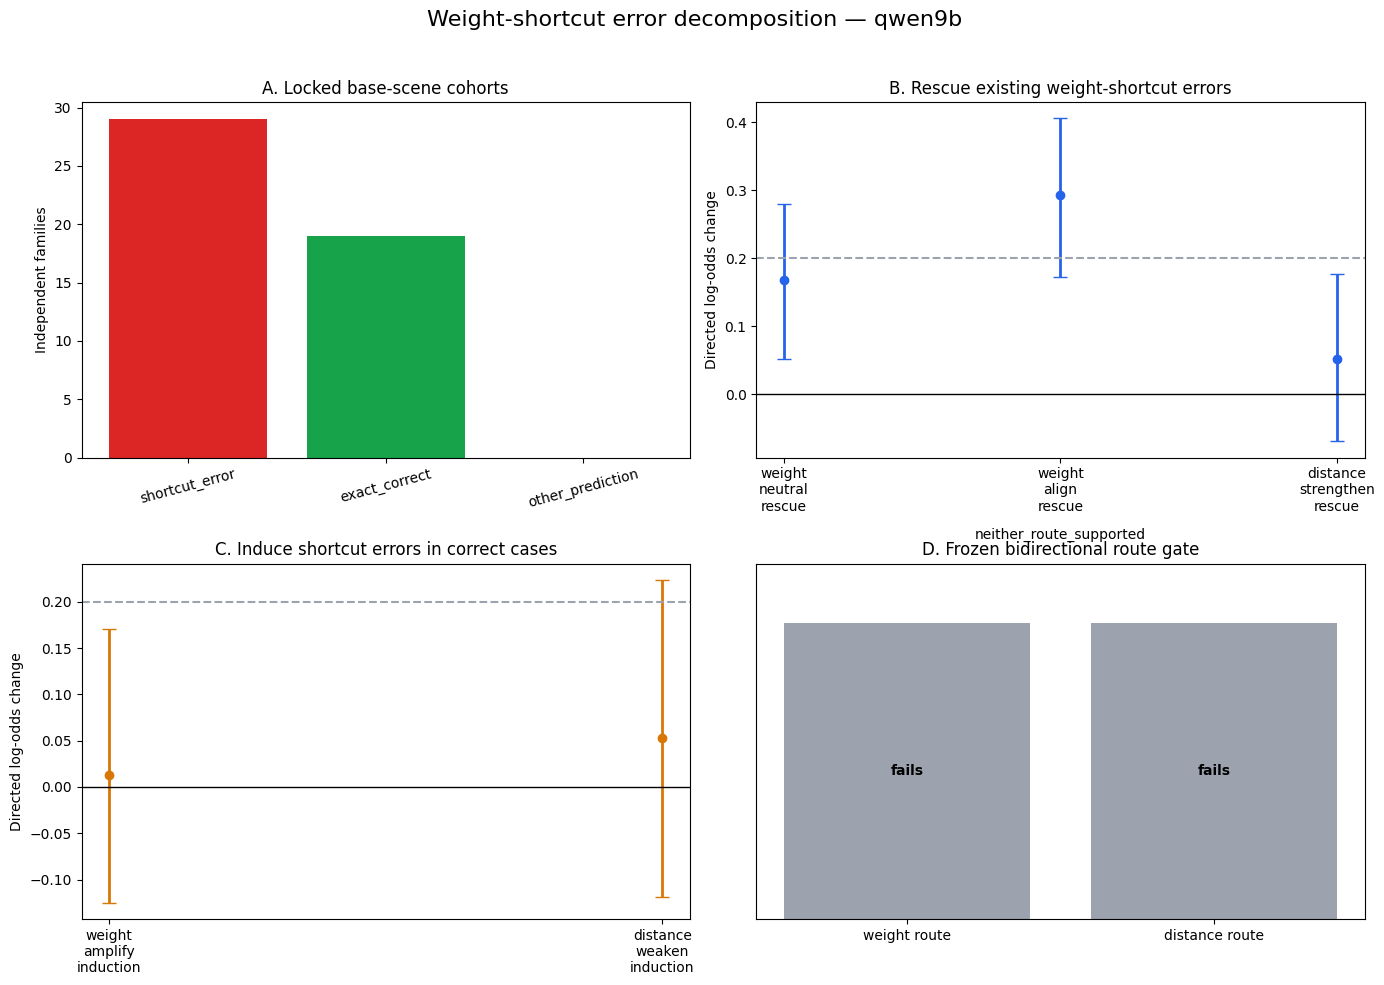

Figure: /content/drive/MyDrive/VisualTorque/results/weight_shortcut_error_decomposition_v1/models/Qwen__Qwen3.5-9B/analysis/figures/weight_shortcut_decomposition.png


In [16]:
%%cell_progress 15/17 Save the paper-facing decomposition figure
cell_stage('Rendering behavior, rescue, induction, and mechanism panels')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cohorts = estimand_frame[
    estimand_frame['site_label'] == PRIMARY_SITE_LABEL
]['baseline_group'].value_counts()
cohort_order = ['shortcut_error', 'exact_correct', 'other_prediction']
axes[0, 0].bar(
    cohort_order, [int(cohorts.get(name, 0)) for name in cohort_order],
    color=['#DC2626', '#16A34A', '#6B7280'],
)
axes[0, 0].set_title('A. Locked base-scene cohorts')
axes[0, 0].set_ylabel('Independent families')
axes[0, 0].tick_params(axis='x', rotation=15)

def plot_effects(axis, direction, title, color):
    rows = tests_frame[
        (tests_frame['site_label'] == PRIMARY_SITE_LABEL)
        & (tests_frame['direction'] == direction)
        & (tests_frame['contrast'] == 'main')
    ].copy()
    order = (
        ['weight_neutral_rescue', 'weight_align_rescue',
         'distance_strengthen_rescue']
        if direction == 'rescue'
        else ['weight_amplify_induction', 'distance_weaken_induction']
    )
    rows = rows.set_index('route_name').reindex(order).reset_index()
    x = np.arange(len(rows))
    y = rows['mean'].to_numpy(float)
    low = y - rows['ci_low'].to_numpy(float)
    high = rows['ci_high'].to_numpy(float) - y
    finite = np.isfinite(y) & np.isfinite(low) & np.isfinite(high)
    if bool(finite.any()):
        axis.errorbar(
            x[finite], y[finite],
            yerr=np.vstack([low[finite], high[finite]]), fmt='o',
            color=color, capsize=5, linewidth=2,
        )
    for index in x[~finite]:
        axis.text(index, 0.02, 'underpowered', ha='center', va='bottom',
                  rotation=90, color='#6B7280')
    axis.axhline(0, color='black', linewidth=1)
    axis.axhline(CAUSAL_SESOI_LOGODDS, color='#9CA3AF', linestyle='--')
    axis.set_xticks(x, [name.replace('_', '\n') for name in order])
    axis.set_ylabel('Directed log-odds change')
    axis.set_title(title)

plot_effects(axes[0, 1], 'rescue', 'B. Rescue existing weight-shortcut errors', '#2563EB')
plot_effects(axes[1, 0], 'induction', 'C. Induce shortcut errors in correct cases', '#D97706')

status = decision_frame.iloc[0]
route_names = ['weight route', 'distance route']
powered = [status['weight_route_powered'], status['distance_route_powered']]
passed = [status['weight_route_passed'], status['distance_route_passed']]
colors = [
    '#16A34A' if passed[index] else '#9CA3AF' if powered[index] else '#F59E0B'
    for index in range(2)
]
axes[1, 1].bar(route_names, [1, 1], color=colors)
axes[1, 1].set_ylim(0, 1.2)
axes[1, 1].set_yticks([])
axes[1, 1].set_title('D. Frozen bidirectional route gate')
for index, name in enumerate(route_names):
    label = 'passes' if passed[index] else 'fails' if powered[index] else 'underpowered'
    axes[1, 1].text(index, 0.5, label, ha='center', va='center',
                    color='white' if passed[index] else 'black', fontweight='bold')
axes[1, 1].text(
    0.5, 1.08, str(status['mechanism_class']),
    ha='center', va='center', transform=axes[1, 1].transAxes,
)

fig.suptitle(f'Weight-shortcut error decomposition — {MODEL_KEY}', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
figure_path = FIGURE_DIR / 'weight_shortcut_decomposition.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Figure:', figure_path)


In [17]:
%%cell_progress 16/17 Write the model mechanism card
cell_stage('Writing the preregistered mechanism classification and claim boundary')

mechanism_class = str(decision_frame.iloc[0]['mechanism_class'])
interpretations = {
    'weight_overuse_supported': (
        'At the frozen factor-composition site, weakening the misleading '
        'weight route repaired existing errors and strengthening it induced '
        'matching errors, while the equally strong distance route did not '
        'pass its full bidirectional gate. This supports overuse of weight.'
    ),
    'distance_underuse_supported': (
        'Strengthening correct distance information repaired existing errors '
        'and weakening it induced matching errors, while the weight route did '
        'not pass its full bidirectional gate. This supports underuse of distance.'
    ),
    'joint_weight_distance_competition': (
        'Both bidirectional routes passed. Weight-shortcut errors are best '
        'described as an imbalance between competing weight and distance '
        'evidence, not as a failure of only one factor.'
    ),
    'directional_only_not_bidirectional': (
        'At least one intervention direction was selective, but no explanation '
        'both repaired and induced the specified error. Report a causal bias, '
        'not a complete mechanism of the error.'
    ),
    'underpowered_for_full_decomposition': (
        'The locked scenes did not yield at least eight existing errors and '
        'eight initially correct cases. The bidirectional comparison is '
        'underpowered and cannot distinguish the two explanations.'
    ),
    'neither_route_supported': (
        'Neither weight nor distance passed the frozen bidirectional gate '
        'beyond matched random perturbations. The earlier rescue does not '
        'reduce to either simple explanation at this site.'
    ),
}
interpretation = interpretations[mechanism_class]

decision_payload = {
    'schema_version': 'weight-shortcut-decomposition-decision-1.0',
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'confirmatory_model': bool(SPEC['confirmatory']),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'capture_identity_sha256': CAPTURE_SHA256,
    'mechanism_class': mechanism_class,
    'route_status': json.loads(decision_frame.to_json(orient='records'))[0],
    'direction_status': direction_status,
    'interpretation': interpretation,
    'robustness_audit': robustness_payload,
    'family_count': int(len(decomposition_manifest)),
    'limitations': [
        'The claim concerns one specified weight-conflict error class.',
        'The primary causal claim is local to a frozen decoder layer and token scope.',
        'Equal net torque and answer prevent donor-answer or margin copying, but do not identify a unique circuit.',
        'A missing correct or error cohort is underpowered rather than negative evidence.',
        'Gemma 12B is an optional boundary audit and not part of the primary two-model gate.',
    ],
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
}
write_json_atomic(ANALYSIS_DIR / 'mechanism_decision.json', decision_payload)

report_lines = [
    f'# Weight-shortcut error decomposition: {MODEL_KEY}', '',
    f'Mechanism class: **{mechanism_class}**', '',
    interpretation, '',
    '## Why this experiment is stronger than the previous rescue', '',
    'Every donor keeps the exact net torque and correct answer unchanged. '
    'Weight edits hold distances fixed; distance edits hold weights fixed; '
    'and competing directions are activation-norm matched.', '',
    '## Directional gates', '',
]
for name, status in direction_status.items():
    report_lines.append(
        f"- {name}: passed={status['passed']}, powered={status['powered']}, "
        f"n={status['n']}, mean={status['mean']:.3f}, "
        f"95% CI=[{status['ci_low']:.3f}, {status['ci_high']:.3f}]"
    )
report_lines.extend([
    '', '## Claim boundary', '',
    'A passing route provides a causal explanation for this error class at '
    'the frozen site. It does not imply that all model errors have one cause '
    'or that the model implements a single serial physics algorithm.',
])
(ANALYSIS_DIR / 'REPORT.md').write_text(
    '\n'.join(report_lines) + '\n', encoding='utf-8'
)
display(decision_payload)
print('Report:', ANALYSIS_DIR / 'REPORT.md')


Write the model mechanism card:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{'schema_version': 'weight-shortcut-decomposition-decision-1.0',
 'model_key': 'qwen9b',
 'model_id': 'Qwen/Qwen3.5-9B',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'confirmatory_model': True,
 'manifest_sha256': 'sha256:5bec9b51bbf5696c29a97de9b04583399abaaf46f534899c18c1a2d53032699b',
 'capture_identity_sha256': 'sha256:93b530649250a3294113aef44ec783db0973b6e64b33315163e1f9efde92b093',
 'mechanism_class': 'neither_route_supported',
 'route_status': {'model_key': 'qwen9b',
  'confirmatory_model': True,
  'mechanism_class': 'neither_route_supported',
  'weight_route_powered': True,
  'weight_route_passed': False,
  'distance_route_powered': True,
  'distance_route_passed': False,
  'weight_rescue_n': 29,
  'weight_induction_n': 19,
  'distance_rescue_n': 29,
  'distance_induction_n': 19},
 'direction_status': {'weight_neutral_rescue': {'powered': True,
   'passed': False,
   'n': 29,
   'mean': 0.16810345598335924,
   'ci_low': 0.05172414919682618,
   'ci_high': 

Report: /content/drive/MyDrive/VisualTorque/results/weight_shortcut_error_decomposition_v1/models/Qwen__Qwen3.5-9B/analysis/REPORT.md


In [18]:
%%cell_progress 17/17 Run the optional exact-manifest cross-model synthesis
cell_stage('Checking confirmatory Qwen decisions on the identical manifest')

decision_paths = {
    key: (
        SHARED_ROOT / 'models' / spec['model_slug']
        / 'analysis' / 'mechanism_decision.json'
    )
    for key, spec in MODEL_SPECS.items()
}
available = {
    key: json.loads(path.read_text(encoding='utf-8'))
    for key, path in decision_paths.items() if path.is_file()
}
print('Available model decisions:', sorted(available))

if all(key in available for key in PRIMARY_MODEL_KEYS):
    hashes = {available[key]['manifest_sha256'] for key in PRIMARY_MODEL_KEYS}
    assert len(hashes) == 1
    rows = []
    for key in (*PRIMARY_MODEL_KEYS, 'gemma12b'):
        if key not in available:
            continue
        payload = available[key]
        status = payload['route_status']
        rows.append({
            'model_key': key,
            'confirmatory_model': key in PRIMARY_MODEL_KEYS,
            'mechanism_class': payload['mechanism_class'],
            'weight_route_passed': status['weight_route_passed'],
            'distance_route_passed': status['distance_route_passed'],
            'weight_rescue_n': status['weight_rescue_n'],
            'weight_induction_n': status['weight_induction_n'],
        })
    cross_frame = pd.DataFrame(rows)
    cross_frame.to_csv(
        CROSS_MODEL_DIR / 'cross_model_mechanism_classification.csv', index=False
    )
    qwen_classes = {
        available[key]['mechanism_class'] for key in PRIMARY_MODEL_KEYS
    }
    if len(qwen_classes) == 1:
        conclusion = (
            'The two Qwen scales yield the same mechanism classification on '
            'the identical independent manifest.'
        )
    else:
        conclusion = (
            'The two Qwen scales yield different mechanism classifications; '
            'scaling changes the balance between weight and distance routes.'
        )
    write_json_atomic(CROSS_MODEL_DIR / 'cross_model_decision.json', {
        'schema_version': 'weight-shortcut-decomposition-cross-model-1.0',
        'shared_manifest_sha256': next(iter(hashes)),
        'primary_models': list(PRIMARY_MODEL_KEYS),
        'model_classes': {
            key: available[key]['mechanism_class']
            for key in PRIMARY_MODEL_KEYS
        },
        'conclusion': conclusion,
        'interpretation_limit': (
            'Compare route classifications, not pooled activation magnitudes '
            'across architectures or depths.'
        ),
    })
    display(cross_frame)
    print(conclusion)
    print('Cross-model outputs:', CROSS_MODEL_DIR)
else:
    missing = [key for key in PRIMARY_MODEL_KEYS if key not in available]
    print('Cross-model synthesis deferred. Still run:', missing)


Run the optional exact-manifest cross-model synthesis:  94%|#########4| 16/17 [00:00<?, ?cell/s]

Available model decisions: ['qwen9b']
Cross-model synthesis deferred. Still run: ['qwen27b']
